In [1]:
# Step : Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


# ***1. Data Understanding*** #

# Step 1.1 Load the Data

In [2]:
# Step : Load the data
path = '/content/drive/MyDrive/Rakamin Intern_Id x partner/loan_data_2007_2014.csv'
df = pd.read_csv(path, low_memory=False)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466285 entries, 0 to 466284
Data columns (total 75 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Unnamed: 0                   466285 non-null  int64  
 1   id                           466285 non-null  int64  
 2   member_id                    466285 non-null  int64  
 3   loan_amnt                    466285 non-null  int64  
 4   funded_amnt                  466285 non-null  int64  
 5   funded_amnt_inv              466285 non-null  float64
 6   term                         466285 non-null  object 
 7   int_rate                     466285 non-null  float64
 8   installment                  466285 non-null  float64
 9   grade                        466285 non-null  object 
 10  sub_grade                    466285 non-null  object 
 11  emp_title                    438697 non-null  object 
 12  emp_length                   445277 non-null  object 
 13 

In [3]:
results = {}

print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
print(f"Duplikat id  : {df['id'].duplicated().sum()}")
print(f"Duplikat member_id : {df['member_id'].duplicated().sum()}")
print("\nTipe data:", df.dtypes.astype(str).value_counts().to_dict())

results["n_rows_raw"] = int(df.shape[0])
results["n_cols_raw"] = int(df.shape[1])

Jumlah baris : 466,285
Jumlah kolom : 75
Duplikat id  : 0
Duplikat member_id : 0

Tipe data: {'float64': 46, 'object': 22, 'int64': 7}


In [4]:
missing = df.isna().mean().sort_values(ascending=False)
print("Kolom 100% kosong:", int((missing == 1).sum()))
print(missing[missing == 1].index.tolist())
print("\nKolom kosong sebagian:")
print((missing[(missing > 0) & (missing < 1)] * 100).round(1).to_string())
print("\nKolom dengan satu nilai saja:", [c for c in df.columns if df[c].nunique() == 1])

Kolom 100% kosong: 17
['max_bal_bc', 'open_rv_24m', 'inq_fi', 'open_rv_12m', 'il_util', 'mths_since_rcnt_il', 'total_bal_il', 'open_il_24m', 'open_il_12m', 'open_il_6m', 'open_acc_6m', 'dti_joint', 'annual_inc_joint', 'verification_status_joint', 'all_util', 'inq_last_12m', 'total_cu_tl']

Kolom kosong sebagian:
mths_since_last_record         86.6
mths_since_last_major_derog    78.8
desc                           73.0
mths_since_last_delinq         53.7
next_pymnt_d                   48.7
tot_coll_amt                   15.1
total_rev_hi_lim               15.1
tot_cur_bal                    15.1
emp_title                       5.9
emp_length                      4.5
last_pymnt_d                    0.1
revol_util                      0.1
collections_12_mths_ex_med      0.0
last_credit_pull_d              0.0
delinq_2yrs                     0.0
acc_now_delinq                  0.0
pub_rec                         0.0
inq_last_6mths                  0.0
earliest_cr_line                0.0
op

### step 1.2 Mengelompokkan atribut #

Berdasarkan data dictionary, kolom dibagi menurut **kapan informasinya tersedia**. Ini
keputusan terpenting dalam project: model dipakai saat pengajuan, jadi kolom yang baru
terisi setelah pinjaman berjalan tidak boleh dipakai (*data leakage*).

| Kelompok | Kolom | Keputusan |
|---|---|---|
| Identitas | `Unnamed: 0`, `id`, `member_id`, `url` | Buang, tidak punya makna prediktif |
| Teks bebas | `emp_title`, `desc`, `title` | Buang, kardinalitas sangat tinggi |
| Wilayah | `zip_code`, `addr_state` | Buang, berisiko menjadi proksi diskriminasi wilayah |
| Kosong atau konstan | 17 kolom kosong (termasuk data joint), `policy_code`, `application_type` | Buang |
| **Setelah pencairan (leakage)** | `out_prncp*`, `total_pymnt*`, `total_rec_*`, `recoveries`, `collection_recovery_fee`, `last_pymnt_*`, `next_pymnt_d`, `last_credit_pull_d`, `pymnt_plan`, `funded_amnt*` | Buang |
| Keputusan platform | `initial_list_status` | Buang, porsi `w` naik dari 0% ke 50% seiring waktu sehingga menjadi proksi era |
| Era-dependent | `mths_since_last_major_derog` | Buang, baru terisi sejak sekitar 2012 |
| Hasil skoring LC | `grade`, `int_rate` | `sub_grade` dipakai sebagai angka ordinal, keduanya dibuang karena redundan. Dampaknya diuji di bagian 5.6 |
| Profil pinjaman dan kredit | sisanya | Dipakai |

**Catatan data dictionary.** Beberapa deskripsi tidak cocok dengan isinya: `loan_amnt`
tertulis "Last month payment was received", `int_rate` di Sheet3 tertulis soal verifikasi
pendapatan, dan `annual_inc` di LoanStats hanya berisi "v". Untuk kolom ini, arti ditentukan
dari nama kolom dan isi datanya.

**Catatan cakupan data.** Brief menyebut data pinjaman "disetujui dan ditolak", tetapi CSV
hanya berisi pinjaman yang **disetujui**. Akibatnya model tidak pernah melihat peminjam
yang ditolak (*selection bias*).

# Step 1.3 Statistik Deskriptif

In [5]:

num_preview = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "delinq_2yrs",
               "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc"]
print(df[num_preview].describe(percentiles=[.01, .5, .99]).T.round(2).to_string())

                   count      mean       std      min        1%       50%        99%         max
loan_amnt       466285.0  14317.28   8286.51   500.00   1750.00  12000.00   35000.00    35000.00
int_rate        466285.0     13.83      4.36     5.42      6.03     13.66      24.89       26.06
installment     466285.0    432.06    243.49    15.67     57.39    379.89    1190.28     1409.99
annual_inc      466281.0  73277.38  54963.57  1896.00  18700.00  63000.00  244000.00  7500000.00
dti             466285.0     17.22      7.85     0.00      1.68     16.87      34.67       39.99
delinq_2yrs     466256.0      0.28      0.80     0.00      0.00      0.00       4.00       29.00
inq_last_6mths  466256.0      0.80      1.09     0.00      0.00      0.00       4.00       33.00
open_acc        466256.0     11.19      4.99     0.00      3.00     10.00      27.00       84.00
pub_rec         466256.0      0.16      0.51     0.00      0.00      0.00       2.00       63.00
revol_bal       466285.0  1623

Median pinjaman **\$12.000**, median pendapatan **\$63.000**, dan median suku bunga **13,66%**.

Perhatikan jarak persentil 99 dan nilai maksimum: 99% peminjam berpendapatan di bawah \$244.000, tetapi maksimumnya \$7,5 juta. `revol_util` juga mencapai 892,3%, padahal 99% datanya di bawah 97,9%. Inilah outlier yang nanti dibatasi dengan winsorizing.

### 1.4 Menentukan target GOOD atau BAD

Kolom performa kredit adalah `loan_status`.

| Status | Label | Alasan |
|---|---|---|
| Fully Paid, Does not meet policy: Fully Paid | **GOOD (0)** | Lunas |
| Charged Off, Default, Does not meet policy: Charged Off | **BAD (1)** | Gagal bayar |
| Late (31-120 days) | **BAD (1)** | Menunggak lebih dari 30 hari |
| Late (16-30 days), In Grace Period | Dikeluarkan | Belum jelas akan lunas atau gagal |
| Current | Dikeluarkan | Masih berjalan, hasil akhirnya belum diketahui |

In [6]:
BAD_STATUS = ["Charged Off", "Default", "Late (31-120 days)",
              "Does not meet the credit policy. Status:Charged Off"]
GOOD_STATUS = ["Fully Paid", "Does not meet the credit policy. Status:Fully Paid"]

loan_labeled = df[df["loan_status"].isin(BAD_STATUS + GOOD_STATUS)].copy()
loan_labeled["target"] = loan_labeled["loan_status"].isin(BAD_STATUS).astype(int)
loan_labeled["issue_dt"] = pd.to_datetime(loan_labeled["issue_d"], format="%b-%y")

print(df["loan_status"].value_counts().to_string())
print(f"\nBaris berlabel : {len(loan_labeled):,} dari {len(df):,}")
print(f"Bad rate       : {loan_labeled['target'].mean():.2%}")
results["n_labeled"] = int(len(loan_labeled))
results["bad_rate_labeled"] = float(loan_labeled["target"].mean())

loan_status
Current                                                224226
Fully Paid                                             184739
Charged Off                                             42475
Late (31-120 days)                                       6900
In Grace Period                                          3146
Does not meet the credit policy. Status:Fully Paid       1988
Late (16-30 days)                                        1218
Default                                                   832
Does not meet the credit policy. Status:Charged Off       761

Baris berlabel : 237,695 dari 466,285
Bad rate       : 21.44%


Status terbanyak adalah `Current` (224.226), yaitu pinjaman yang masih berjalan dan belum diketahui hasilnya. Setelah status yang belum jelas dikeluarkan, tersisa **237.695 pinjaman berlabel** dengan **bad rate 21,44%**. Artinya sekitar 1 dari 5 pinjaman berakhir buruk, sehingga datanya tidak seimbang tetapi kelas BAD masih cukup banyak untuk dipelajari.

## 2. Exploratory Data Analysis
### 2.1 Komposisi status dan bias waktu

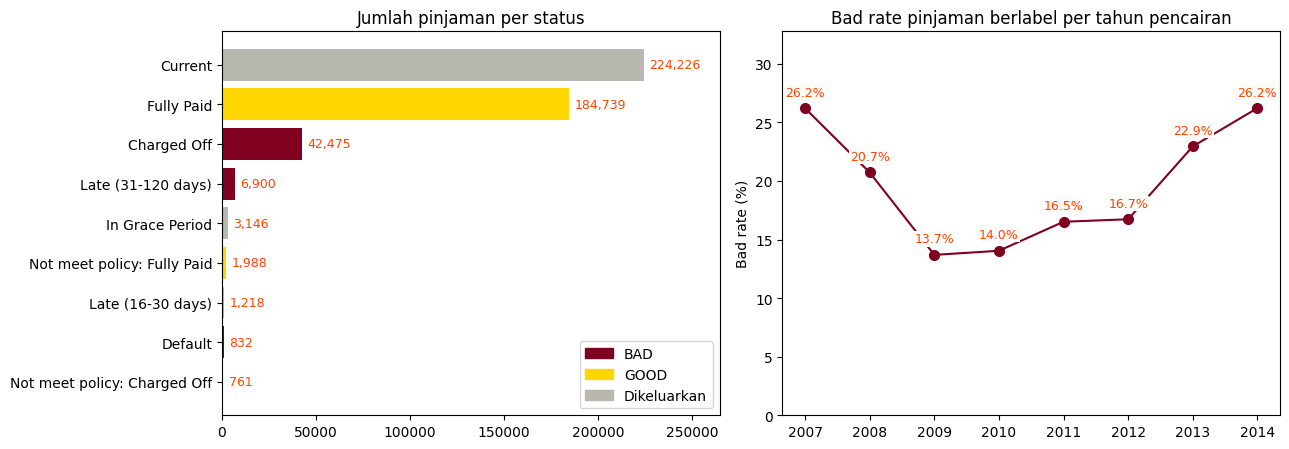

Porsi status Current per tahun (%):
y
2007     0.0
2008     0.0
2009     0.0
2010     0.1
2011     9.0
2012     6.5
2013    44.7
2014    67.3

Bad rate kohort matang (tenor 36 bulan, cair sampai 2012): 13.09%, n=74,959


In [7]:
C_BAD = "#800020"
C_GOOD = "#FFD700"
C_MUTED = "#FF4500"
OUTPUT_DIR = "."

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

group = df["loan_status"].map(
    lambda s: "BAD" if s in BAD_STATUS else ("GOOD" if s in GOOD_STATUS else "Dikeluarkan"))
counts = df.groupby(["loan_status"]).size().sort_values()
color_map = {"BAD": C_BAD, "GOOD": C_GOOD, "Dikeluarkan": "#b8b7b0"}
labels = [s.replace("Does not meet the credit policy. Status:", "Not meet policy: ") for s in counts.index]
axes[0].barh(labels, counts.values, color=[color_map[group[df["loan_status"] == s].iloc[0]] for s in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(v + 3000, i, f"{v:,}", va="center", fontsize=9, color=C_MUTED)
axes[0].set_title("Jumlah pinjaman per status")
axes[0].set_xlim(0, counts.max() * 1.18)
axes[0].grid(axis="y", visible=False)
axes[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=color_map[k]) for k in color_map],
               labels=list(color_map), loc="lower right")

vintage = loan_labeled.groupby(loan_labeled["issue_dt"].dt.year)["target"].mean() * 100
axes[1].plot(vintage.index, vintage.values, color=C_BAD, marker="o", markersize=7)
for x, y in vintage.items():
    axes[1].annotate(f"{y:.1f}%", (x, y), textcoords="offset points", xytext=(0, 9),
                     ha="center", fontsize=9, color=C_MUTED, bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=0.8))
axes[1].set_title("Bad rate pinjaman berlabel per tahun pencairan")
axes[1].set_ylabel("Bad rate (%)")
axes[1].set_ylim(0, vintage.max() * 1.25)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/01_status_vintage.png", dpi=150, bbox_inches="tight")
plt.show()

current_share = df.assign(y=pd.to_datetime(df["issue_d"], format="%b-%y").dt.year)
current_share = (current_share["loan_status"] == "Current").groupby(current_share["y"]).mean() * 100
print("Porsi status Current per tahun (%):")
print(current_share.round(1).to_string())

matured = loan_labeled[(loan_labeled["term"].str.strip() == "36 months") & (loan_labeled["issue_dt"] <= "2012-12-31")]
print(f"\nBad rate kohort matang (tenor 36 bulan, cair sampai 2012): {matured['target'].mean():.2%}, n={len(matured):,}")
results["bad_rate_matured"] = float(matured["target"].mean())
results["vintage_bad_rate"] = {int(k): float(v) for k, v in vintage.items()}

**Penjelasan hasil**

**Grafik kiri** menunjukkan jumlah pinjaman per status: kuning GOOD, merah BAD, abu-abu dikeluarkan. Hampir separuh data adalah `Current`.

**Grafik kanan** menunjukkan bad rate naik tajam pada 2013 dan 2014. Tabel di bawah grafik menjelaskan sebabnya: 67,3% pinjaman 2014 masih berjalan. Pada pinjaman yang sudah terpantau penuh, bad rate hanya **13,09%** dari 74.959 pinjaman.

**Insight: bad rate yang naik di 2013-2014 sebagian besar adalah bias pengamatan.**
Data dipotong sekitar Januari 2016, sehingga 67,3% pinjaman 2014 masih `Current` dan
dikeluarkan. Pinjaman 2014 yang sudah berakhir didominasi yang cepat gagal atau cepat lunas.
Kohort yang sudah terpantau penuh (tenor 36 bulan, cair sampai 2012) hanya punya bad rate
**13,09%**, jauh di bawah 26,2% pada 2014. Akibatnya bad rate dan arus kas pada test set tidak
boleh dibaca sebagai tingkat gagal bayar sebenarnya.

### 2.2 Analisis univariat dan bivariat: fitur numerik

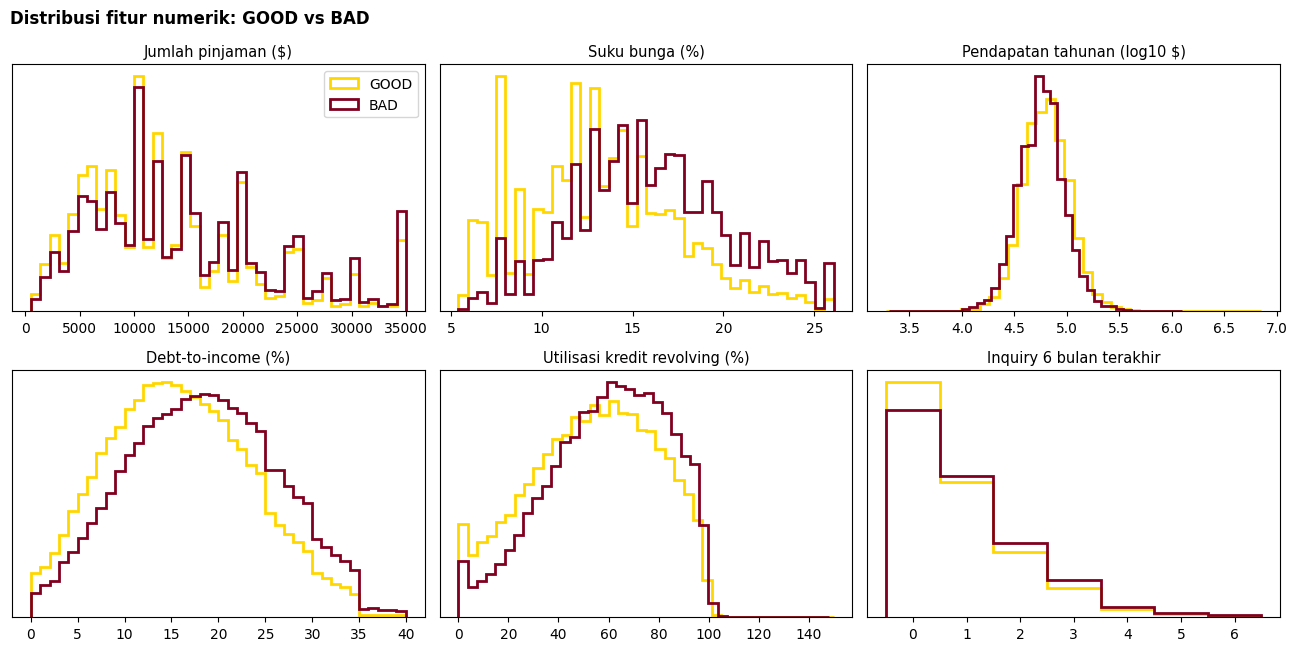

target              GOOD       BAD
loan_amnt       11625.00  12800.00
int_rate           13.11     15.61
annual_inc      64000.00  56300.00
dti                15.57     18.28
revol_util         55.20     61.60
inq_last_6mths      1.00      1.00


In [8]:
plot_df = loan_labeled.assign(
    log_income=np.log10(loan_labeled["annual_inc"].clip(lower=1000)),
    revol_util_cap=loan_labeled["revol_util"].clip(upper=150),
)
panels = [("loan_amnt", "Jumlah pinjaman ($)"), ("int_rate", "Suku bunga (%)"),
          ("log_income", "Pendapatan tahunan (log10 $)"), ("dti", "Debt-to-income (%)"),
          ("revol_util_cap", "Utilisasi kredit revolving (%)"), ("inq_last_6mths", "Inquiry 6 bulan terakhir")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6))
for ax, (col, label) in zip(axes.ravel(), panels):
    s = plot_df[[col, "target"]].dropna()
    if col == "inq_last_6mths":
        s = s[s[col] <= 6]
    bins = np.arange(-0.5, 7.5, 1) if col == "inq_last_6mths" else 40
    ax.hist(s.loc[s.target == 0, col], bins=bins, density=True, histtype="step", color=C_GOOD, linewidth=2, label="GOOD")
    ax.hist(s.loc[s.target == 1, col], bins=bins, density=True, histtype="step", color=C_BAD, linewidth=2, label="BAD")
    ax.set_title(label, fontsize=10.5)
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].legend()
fig.suptitle("Distribusi fitur numerik: GOOD vs BAD", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/02_distribusi_numerik.png", dpi=150, bbox_inches="tight")
plt.show()

print(loan_labeled.groupby("target")[["loan_amnt", "int_rate", "annual_inc", "dti", "revol_util", "inq_last_6mths"]].median().T.rename(columns={0: "GOOD", 1: "BAD"}).to_string())

**Penjelasan hasil**

Garis kuning (GOOD) dan merah (BAD) yang makin terpisah berarti fitur itu makin bisa membedakan risiko.

- **Suku bunga** paling terlihat bedanya: median BAD 15,61%, GOOD 13,11%.
- **DTI** dan **utilisasi kredit** bergeser ke kanan pada BAD, artinya peminjam BAD cenderung lebih berat bebannya (median DTI 18,28 berbanding 15,57).
- **Pendapatan** BAD sedikit lebih rendah (\$56.300 berbanding \$64.000), tetapi kedua kurvanya banyak bertumpuk.
- **Jumlah pinjaman** punya lonjakan di angka bulat seperti \$10.000 dan \$35.000, karena orang cenderung meminjam angka bulat.

Tidak ada satu fitur yang memisahkan GOOD dan BAD dengan sempurna, jadi model perlu menggabungkan banyak fitur.

### 2.3 Analisis bivariat: fitur kategorikal terhadap bad rate

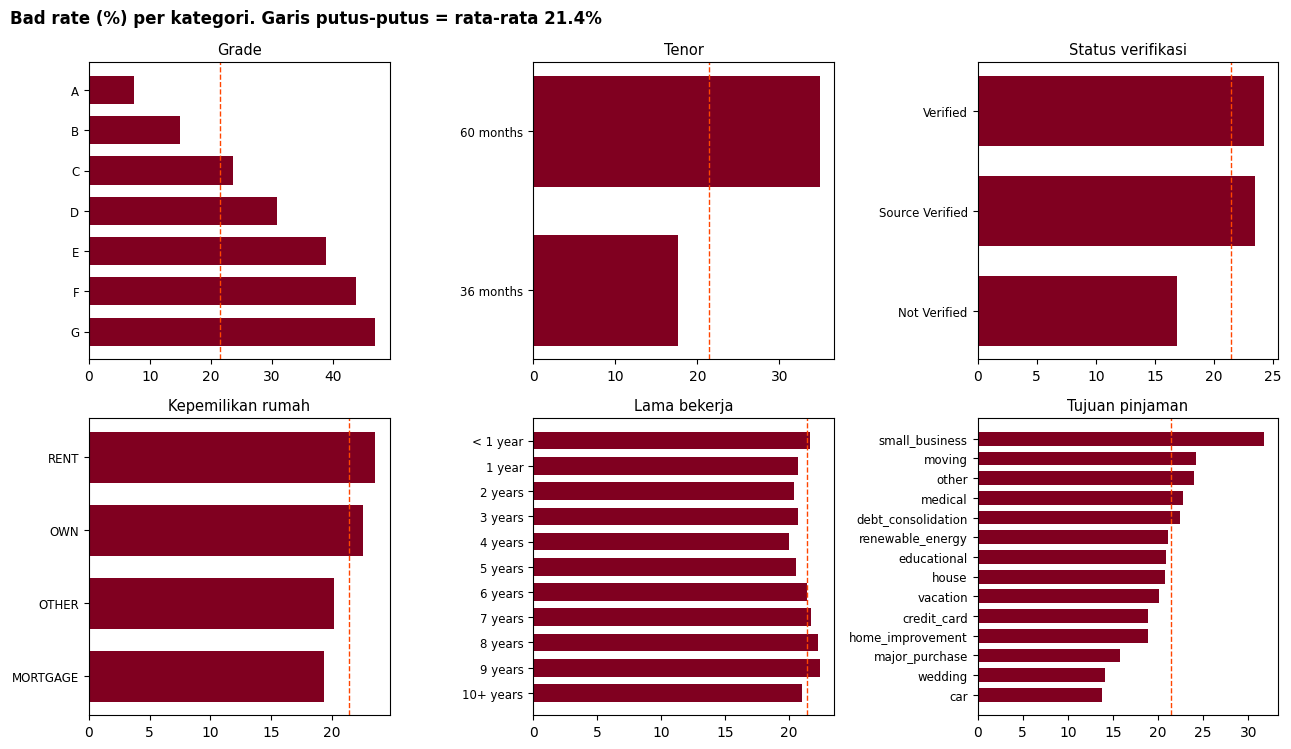

A    0.0734
B    0.1495
C    0.2370
D    0.3083
E    0.3888
F    0.4389
G    0.4702
36 months    0.1767
60 months    0.3492


In [9]:
emp_order = ["< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years", "6 years",
             "7 years", "8 years", "9 years", "10+ years"]
home = loan_labeled["home_ownership"].replace({"NONE": "OTHER", "ANY": "OTHER"})
cats = [("Grade", loan_labeled["grade"], sorted(loan_labeled["grade"].unique())),
        ("Tenor", loan_labeled["term"].str.strip(), None),
        ("Status verifikasi", loan_labeled["verification_status"], None),
        ("Kepemilikan rumah", home, None),
        ("Lama bekerja", loan_labeled["emp_length"], emp_order),
        ("Tujuan pinjaman", loan_labeled["purpose"], None)]
fig, axes = plt.subplots(2, 3, figsize=(13, 7.6))
overall = loan_labeled["target"].mean() * 100
for ax, (title, s, order) in zip(axes.ravel(), cats):
    rate = loan_labeled["target"].groupby(s).mean() * 100
    rate = rate.reindex(order) if order else rate.sort_values(ascending=True)
    ax.barh(rate.index.astype(str), rate.values, color=C_BAD, height=0.7)
    ax.axvline(overall, color=C_MUTED, linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)
    if order:
        ax.invert_yaxis()
fig.suptitle(f"Bad rate (%) per kategori. Garis putus-putus = rata-rata {overall:.1f}%", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/03_badrate_kategori.png", dpi=150, bbox_inches="tight")
plt.show()

results["bad_rate_by_grade"] = (loan_labeled.groupby("grade")["target"].mean()).round(4).to_dict()
results["bad_rate_by_term"] = (loan_labeled["target"].groupby(loan_labeled["term"].str.strip()).mean()).round(4).to_dict()
results["bad_rate_by_purpose"] = (loan_labeled.groupby("purpose")["target"].mean()).round(4).to_dict()
print(pd.Series(results["bad_rate_by_grade"]).to_string())
print(pd.Series(results["bad_rate_by_term"]).to_string())

**Penjelasan hasil**

Setiap batang adalah bad rate satu kategori, dan garis putus-putus adalah rata-rata 21,4%.

- **Grade:** naik teratur dari 7,34% (A) ke 47,02% (G). Ini pembeda terkuat.
- **Tenor:** 60 bulan 34,92%, sekitar dua kali lipat 36 bulan (17,67%).
- **Verifikasi:** pinjaman `Verified` justru lebih berisiko. Ini berarti ada hubungan, belum tentu sebab-akibat.
- **Lama bekerja:** hampir datar di semua kategori, jadi kurang berguna sebagai pembeda.

### 2.4 Interaksi dua variabel dan korelasi antar fitur

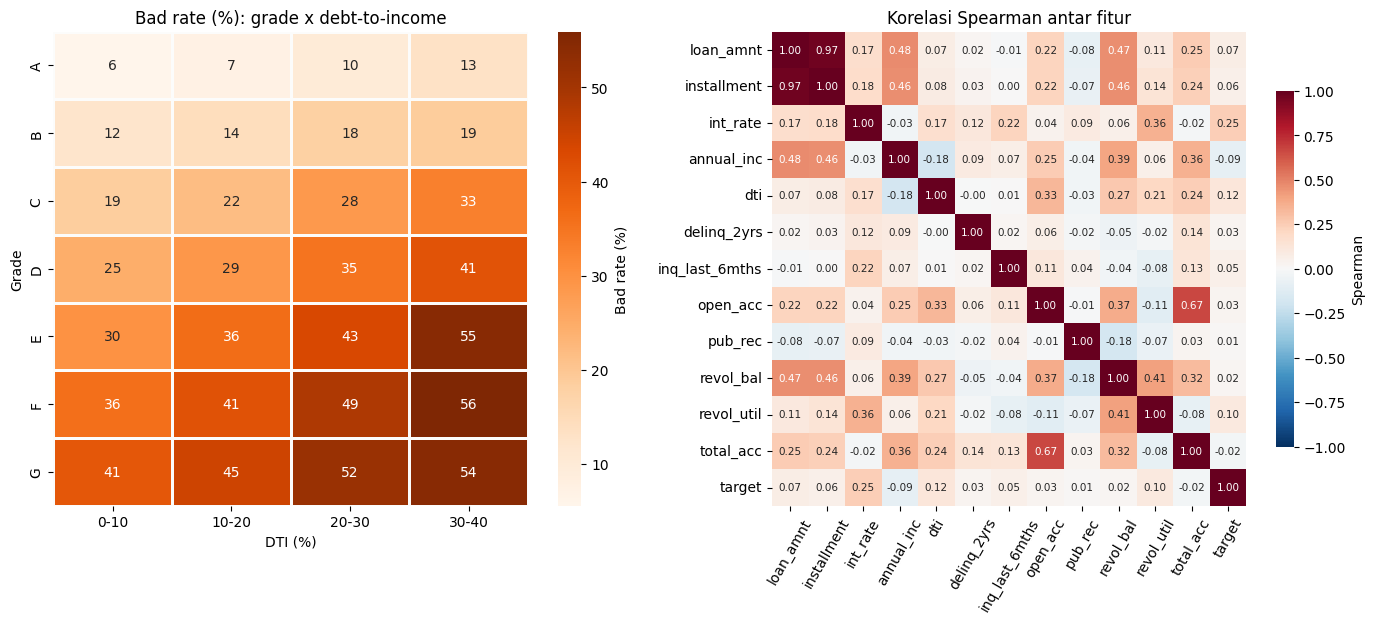

Korelasi terhadap target:
int_rate          0.250
dti               0.124
revol_util        0.096
annual_inc       -0.090
loan_amnt         0.072
installment       0.060
inq_last_6mths    0.055
delinq_2yrs       0.027
open_acc          0.025
total_acc        -0.024
revol_bal         0.016
pub_rec           0.015


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
dti_bin = pd.cut(loan_labeled["dti"], [-1, 10, 20, 30, 40], labels=["0-10", "10-20", "20-30", "30-40"])
pivot = loan_labeled.pivot_table(index="grade", columns=dti_bin, values="target", aggfunc="mean", observed=False) * 100
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Oranges", cbar_kws={"label": "Bad rate (%)"}, ax=axes[0], linewidths=2, linecolor="#fcfcfb")
axes[0].set_title("Bad rate (%): grade x debt-to-income")
axes[0].set_xlabel("DTI (%)")
axes[0].set_ylabel("Grade")

corr_cols = ["loan_amnt", "installment", "int_rate", "annual_inc", "dti", "delinq_2yrs", "inq_last_6mths",
             "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "target"]
corr = loan_labeled[corr_cols].corr(method="spearman")
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            ax=axes[1], square=True, cbar_kws={"shrink": 0.75, "label": "Spearman"})
axes[1].set_title("Korelasi Spearman antar fitur")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/04_interaksi_korelasi.png", dpi=150, bbox_inches="tight")
plt.show()

print("Korelasi terhadap target:")
print(corr["target"].drop("target").sort_values(key=np.abs, ascending=False).round(3).to_string())

**Penjelasan hasil**

**Heatmap kiri** menggabungkan dua fitur. Grade A dengan DTI rendah hanya 6% yang buruk, sedangkan grade E dengan DTI 30-40 mencapai 55%. Artinya risiko makin tinggi kalau grade buruk dan beban utang tinggi terjadi bersamaan.

**Heatmap kanan** menunjukkan hubungan antar fitur. `loan_amnt` dan `installment` hampir sama (0,97), jadi tidak perlu dipakai keduanya apa adanya. Baris `target` menunjukkan korelasi tiap fitur terhadap gagal bayar: tertinggi `int_rate` 0,25, dan `dti` 0,12. Korelasi yang kecil ini wajar untuk data kredit, dan menandakan gagal bayar sulit ditebak dari satu fitur saja.

### 2.5 Segmentasi peminjam dengan K-Means dan PCA

Hints menyarankan clustering untuk melihat struktur data. Clustering memakai profil
peminjam saja, tanpa target, lalu bad rate tiap segmen dihitung setelahnya.

Varians kumulatif PCA: [0.314 0.5   0.666 0.782 0.863 0.919 0.964 1.   ]
Silhouette: {2: np.float64(0.177), 3: np.float64(0.15), 4: np.float64(0.148), 5: np.float64(0.151), 6: np.float64(0.147)}
             n  bad_rate  loan_amnt  annual_inc    dti  open_acc  revol_bal  revol_util  total_acc  inq_last_6mths
cluster                                                                                                           
0         7596     0.159     8000.0     53414.5   9.20       8.0     3554.0        25.4       18.0             1.0
1         9302     0.214    22000.0     95000.0  14.21      11.0    20007.5        65.1       26.0             0.0
2         8874     0.224    12800.0     69000.0  20.91      16.0    14878.5        49.4       37.0             1.0
3        14228     0.241     9750.0     47000.0  18.17       8.0    10029.0        68.8       18.0             0.0


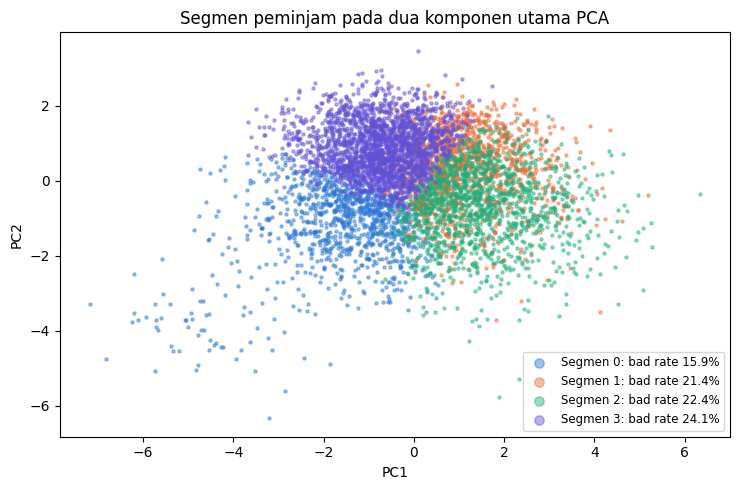

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42

cluster_cols = ["loan_amnt", "annual_inc", "dti", "open_acc", "revol_bal", "revol_util", "total_acc", "inq_last_6mths"]
cl_df = loan_labeled[cluster_cols + ["target"]].dropna().sample(40000, random_state=SEED)
cl_x = cl_df[cluster_cols].copy()
for c in ["annual_inc", "revol_bal"]:
    cl_x[c] = np.log1p(cl_x[c])
cl_scaled = StandardScaler().fit_transform(cl_x.clip(cl_x.quantile(.005), cl_x.quantile(.995), axis=1))

pca = PCA().fit(cl_scaled)
print("Varians kumulatif PCA:", np.cumsum(pca.explained_variance_ratio_).round(3))

sil = {k: silhouette_score(cl_scaled, KMeans(k, n_init=5, random_state=SEED).fit_predict(cl_scaled),
                           sample_size=8000, random_state=SEED) for k in range(2, 7)}
print("Silhouette:", {k: round(v, 3) for k, v in sil.items()})

K = 4
cl_df["cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(cl_scaled)
profile = cl_df.groupby("cluster").agg(n=("target", "size"), bad_rate=("target", "mean"),
                                       **{c: (c, "median") for c in cluster_cols}).round(3)
print(profile.sort_values("bad_rate").to_string())

coords = pca.transform(cl_scaled)[:, :2]
fig, ax = plt.subplots(figsize=(7.5, 5))
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
idx = np.random.RandomState(SEED).choice(len(coords), 6000, replace=False)
for k in range(K):
    m = cl_df["cluster"].values[idx] == k
    ax.scatter(coords[idx][m, 0], coords[idx][m, 1], s=5, alpha=.45, color=palette[k],
               label=f"Segmen {k}: bad rate {profile.loc[k, 'bad_rate']:.1%}")
ax.set_title("Segmen peminjam pada dua komponen utama PCA")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(markerscale=3, fontsize=8.5)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/05_cluster_pca.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

**PCA:** dua komponen pertama hanya menangkap 50% informasi, jadi gambar dua dimensi ini hanya gambaran kasar.

**Silhouette:** nilainya rendah, 0,147 sampai 0,177, artinya kelompok peminjam tidak terpisah tegas. Pada grafik, titiknya memang saling bertumpuk. Nilai tertinggi ada di 2 kelompok, tetapi 4 kelompok dipilih karena profilnya lebih mudah dibaca.

**Profil segmen:** segmen 0 (pinjaman kecil, DTI dan utilisasi rendah) paling aman dengan bad rate 15,9%. Segmen 3 (pendapatan rendah, utilisasi tinggi) paling berisiko dengan 24,1%. Karena selisihnya tidak besar dan pemisahannya lemah, segmen ini tidak dipakai sebagai fitur model.

**Ringkasan insight EDA**

- **Grade paling membedakan:** bad rate naik teratur dari 7,3% (A) sampai 47,0% (G).
- **Tenor:** 60 bulan 34,9% berbanding 36 bulan 17,7%. Sebagian perbedaan ini dipengaruhi bias
  waktu, karena tenor 60 bulan baru ada sejak 2010 dan belum banyak yang jatuh tempo.
- **Tujuan pinjaman:** `small_business` paling berisiko (sekitar 32%), `car` dan `wedding` terendah
  (sekitar 14%).
- **Status verifikasi terbalik dari dugaan:** pinjaman `Verified` lebih berisiko daripada
  `Not Verified`. Kemungkinan verifikasi lebih sering diminta untuk pengajuan yang sudah dinilai
  berisiko, jadi ini bukan berarti verifikasi merugikan.
- **Lama bekerja hampir tidak membedakan:** semua kategori sekitar 20-22%.
- **Korelasi terhadap target lemah secara individual:** tertinggi `int_rate` (0,25) lalu `dti`
  (0,12). Pasangan `loan_amnt` dan `installment` sangat berkorelasi, jadi cicilan dipakai dalam
  bentuk rasio terhadap pendapatan.
- **Segmen K-Means tidak terpisah tegas:** silhouette hanya sekitar 0,15, dan bad rate antar
  segmen 15,9-24,1%. Berguna untuk gambaran profil, tidak dipakai sebagai fitur.

## 3. Data Preparation

### 3.1 Feature engineering

- **Kredit historis:** `earliest_cr_line` memakai dua digit tahun, sehingga 1968 terbaca
  2068. Tanggal setelah pencairan dikurangi 100 tahun.
- **Missing yang bermakna:** `mths_since_last_delinq` dan `mths_since_last_record` kosong
  berarti belum pernah ada kejadian. Dibuat flag, nilainya diisi lewat imputasi median.
- **Rasio beban:** pinjaman dan cicilan dibanding pendapatan.
- **Log transform:** kolom uang yang sangat miring ke kanan.

In [12]:
SUB_GRADES = [f"{g}{i}" for g in "ABCDEFG" for i in range(1, 6)]
SUB_GRADE_MAP = {s: i for i, s in enumerate(SUB_GRADES, start=1)}


def build_features(data):
    """Membuat fitur yang semuanya tersedia saat pengajuan. Tidak ada parameter yang dipelajari dari data."""
    x = pd.DataFrame(index=data.index)
    issue = pd.to_datetime(data["issue_d"], format="%b-%y")
    earliest = pd.to_datetime(data["earliest_cr_line"], format="%b-%y", errors="coerce")
    wrong_century = earliest > issue
    earliest = earliest.where(~wrong_century, earliest - pd.DateOffset(years=100))
    x["credit_history_years"] = (issue - earliest).dt.days / 365.25

    emp = data["emp_length"].str.replace("< 1 year", "0", regex=False).str.extract(r"(\d+)")[0].astype(float)
    x["emp_years"] = emp
    x["emp_length_missing"] = emp.isna().astype(int)

    x["term_60"] = (data["term"].str.strip() == "60 months").astype(int)
    x["sub_grade_num"] = data["sub_grade"].map(SUB_GRADE_MAP).astype(float)
    x["int_rate"] = data["int_rate"]  # hanya untuk uji sensitivitas, lihat FEATURE_DROP
    x["loan_amnt"] = data["loan_amnt"]
    x["dti"] = data["dti"]
    x["revol_util"] = data["revol_util"]
    for c in ["delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec", "total_acc",
              "collections_12_mths_ex_med", "acc_now_delinq"]:
        x[c] = data[c]
    for c in ["annual_inc", "revol_bal", "tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim"]:
        x[f"log_{c}"] = np.log1p(data[c].clip(lower=0))

    income = data["annual_inc"].replace(0, np.nan)
    x["loan_to_income"] = data["loan_amnt"] / income
    x["installment_to_income"] = data["installment"] * 12 / income
    x["revol_bal_to_income"] = data["revol_bal"] / income

    x["had_delinq"] = data["mths_since_last_delinq"].notna().astype(int)
    x["mths_since_last_delinq"] = data["mths_since_last_delinq"]
    x["had_public_record"] = data["mths_since_last_record"].notna().astype(int)
    x["mths_since_last_record"] = data["mths_since_last_record"]

    x["home_ownership"] = data["home_ownership"].replace({"NONE": "OTHER", "ANY": "OTHER"})
    x["verification_status"] = data["verification_status"]
    x["purpose"] = data["purpose"]
    return x


loan_features = build_features(loan_labeled)
y_all = loan_labeled["target"]
CAT_COLS = ["home_ownership", "verification_status", "purpose"]
FEATURE_DROP = ["int_rate"]
print("Jumlah fitur input:", loan_features.shape[1] - len(FEATURE_DROP))
print("Tanggal kredit yang dikoreksi:", int((pd.to_datetime(loan_labeled['earliest_cr_line'], format='%b-%y', errors='coerce') > loan_labeled['issue_dt']).sum()))
print("\nMissing setelah feature engineering (%):")
print((loan_features.isna().mean() * 100).round(1).loc[lambda s: s > 0].to_string())

Jumlah fitur input: 30
Tanggal kredit yang dikoreksi: 513

Missing setelah feature engineering (%):
emp_years                      3.9
revol_util                     0.1
collections_12_mths_ex_med     0.1
log_tot_coll_amt              28.0
log_tot_cur_bal               28.0
log_total_rev_hi_lim          28.0
mths_since_last_delinq        56.0
mths_since_last_record        87.9


**Penjelasan hasil**

Model memakai **30 fitur input**. Ada **513 tanggal kredit** yang diperbaiki karena tahun dua digit salah abad.

Fitur `log_tot_*` kosong 28% karena datanya tidak tersedia untuk sebagian pinjaman lama. `mths_since_last_delinq` (56,0%) dan `mths_since_last_record` (87,9%) kosong karena peminjam kemungkinan belum pernah mengalami kejadian itu, dan informasi tersebut sudah disimpan di flag `had_delinq` dan `had_public_record`.

### 3.2 Pembagian train dan test berdasarkan waktu

Model selalu dipakai pada pinjaman **masa depan**, maka test set harus lebih baru dari
train set: **train = cair sampai Desember 2013, test = cair sepanjang 2014**
(*out-of-time split*). Pembagian acak juga diuji di bagian 5.6 sebagai pembanding.

In [13]:
is_train = loan_labeled["issue_dt"] <= "2013-12-31"
X_train, X_test = loan_features[is_train], loan_features[~is_train]
y_train, y_test = y_all[is_train], y_all[~is_train]
net_train = (loan_labeled["total_pymnt"] - loan_labeled["funded_amnt"])[is_train]  # hanya untuk simulasi bisnis, bukan fitur
net_test = (loan_labeled["total_pymnt"] - loan_labeled["funded_amnt"])[~is_train]

print(f"Train: {len(X_train):,} baris, bad rate {y_train.mean():.2%}, {loan_labeled.issue_dt[is_train].min():%b %Y} s/d {loan_labeled.issue_dt[is_train].max():%b %Y}")
print(f"Test : {len(X_test):,} baris, bad rate {y_test.mean():.2%}, {loan_labeled.issue_dt[~is_train].min():%b %Y} s/d {loan_labeled.issue_dt[~is_train].max():%b %Y}")
results.update(n_train=int(len(X_train)), n_test=int(len(X_test)),
               bad_rate_train=float(y_train.mean()), bad_rate_test=float(y_test.mean()))

Train: 163,541 baris, bad rate 19.28%, Jun 2007 s/d Dec 2013
Test : 74,154 baris, bad rate 26.22%, Jan 2014 s/d Dec 2014


**Penjelasan hasil**

Model belajar dari **163.541** pinjaman sampai Desember 2013, lalu diuji pada **74.154** pinjaman 2014 yang belum pernah dilihat. Bad rate test (26,22%) lebih tinggi dari train (19,28%), sebagian karena bias waktu di bagian 2.1. Jadi pengujian ini lebih berat, tetapi lebih mirip pemakaian nyata.

### 3.3 Pipeline preprocessing

Semua langkah yang mempelajari parameter dari data dipasang di dalam `Pipeline`, sehingga
hanya belajar dari data latih pada setiap fold dan tidak membocorkan informasi test set.

| Masalah | Penanganan | Alasan |
|---|---|---|
| Missing numerik | Imputasi median | Tahan terhadap outlier. Fitur tagihan `tot_*` kosong untuk pinjaman lama, jadi tidak diberi flag agar model tidak mempelajari era |
| Outlier | Winsorizing persentil 0,5 dan 99,5 | Nilai ekstrem seperti pendapatan \$7,5 juta bisa saja benar, jadi baris tidak dihapus, nilainya dibatasi |
| Kategorikal | One-hot encoding | Kategori tidak berurutan, `handle_unknown="ignore"` menjaga kategori baru |
| Skala | StandardScaler | Dibutuhkan Logistic Regression agar regularisasi adil antar fitur |
| Imbalance | Tidak di-resample | Kelas BAD sekitar 21%, masih cukup. Probabilitas tetap terkalibrasi dan cutoff diatur terpisah |

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

class Winsorizer(BaseEstimator, TransformerMixin):
    """Membatasi nilai pada persentil bawah dan atas yang dipelajari dari data latih."""

    def __init__(self, lower=0.005, upper=0.995):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.low_, self.high_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features)


def make_preprocessor(columns, scale=True):
    num_cols = [c for c in columns if c not in CAT_COLS]
    steps = [("impute", SimpleImputer(strategy="median")), ("clip", Winsorizer())]
    if scale:
        steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(steps), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=200), CAT_COLS),
    ])


FEATURES = [c for c in loan_features.columns if c not in FEATURE_DROP]
CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
print(len(FEATURES), "fitur:", FEATURES)

30 fitur: ['credit_history_years', 'emp_years', 'emp_length_missing', 'term_60', 'sub_grade_num', 'loan_amnt', 'dti', 'revol_util', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'total_acc', 'collections_12_mths_ex_med', 'acc_now_delinq', 'log_annual_inc', 'log_revol_bal', 'log_tot_coll_amt', 'log_tot_cur_bal', 'log_total_rev_hi_lim', 'loan_to_income', 'installment_to_income', 'revol_bal_to_income', 'had_delinq', 'mths_since_last_delinq', 'had_public_record', 'mths_since_last_record', 'home_ownership', 'verification_status', 'purpose']


## 4. Data Modelling

| Model | Peran | Alasan |
|---|---|---|
| Logistic Regression (wajib) | Baseline | Mudah dijelaskan ke regulator dan tim kredit, koefisiennya bisa dibaca |
| HistGradientBoosting | Kandidat utama | Menangkap non-linearitas dan interaksi, cepat di data besar |
| Random Forest | Pembanding | Pendekatan ensemble berbeda (bagging) |

Metrik pemilihan adalah **ROC-AUC**, karena tidak bergantung pada cutoff dan standar di
credit scoring. Akurasi tidak dipakai untuk memilih model: menebak semua GOOD saja sudah
memberi akurasi sekitar 79% tanpa manfaat apa pun.

### 4.1 Logistic Regression dengan Grid Search

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

lr_pipe = Pipeline([("prep", make_preprocessor(FEATURES)),
                    ("clf", LogisticRegression(max_iter=2000))])
lr_search = GridSearchCV(lr_pipe, {"clf__C": [0.001, 0.01, 0.1, 1.0]}, scoring="roc_auc", cv=CV, n_jobs=2)
lr_search.fit(X_train[FEATURES], y_train)
print("Parameter terbaik:", lr_search.best_params_)
print(pd.DataFrame(lr_search.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]].round(4).to_string(index=False))

Parameter terbaik: {'clf__C': 0.01}
 param_clf__C  mean_test_score  std_test_score
        0.001           0.7039          0.0018
        0.010           0.7049          0.0020
        0.100           0.7049          0.0021
        1.000           0.7048          0.0021


**Penjelasan hasil**

`C` mengatur seberapa ketat model dibatasi. Nilai terbaik **C = 0,01**, tetapi AUC-nya hampir sama untuk C 0,01 sampai 1 (0,7048-0,7049). Artinya tuning hampir tidak berpengaruh, dan kemampuan Logistic Regression memang sekitar **0,705**.

### 4.2 HistGradientBoosting dengan Randomized Search

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

hgb_pipe = Pipeline([("prep", make_preprocessor(FEATURES, scale=False)),
                     ("clf", HistGradientBoostingClassifier(random_state=SEED))])
hgb_space = {"clf__learning_rate": [0.03, 0.05, 0.1],
             "clf__max_iter": [150, 300, 500],
             "clf__max_leaf_nodes": [7, 15, 31],
             "clf__min_samples_leaf": [50, 200, 500],
             "clf__l2_regularization": [0.0, 1.0, 10.0]}
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_space, n_iter=10, scoring="roc_auc", cv=CV,
                                random_state=SEED, n_jobs=1, return_train_score=True)
hgb_search.fit(X_train[FEATURES], y_train)
print("Parameter terbaik:", hgb_search.best_params_)
cols = ["param_clf__learning_rate", "param_clf__max_iter", "param_clf__max_leaf_nodes",
        "mean_train_score", "mean_test_score"]
print(pd.DataFrame(hgb_search.cv_results_)[cols].sort_values("mean_test_score", ascending=False).round(4).to_string(index=False))

Parameter terbaik: {'clf__min_samples_leaf': 500, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 500, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 10.0}
 param_clf__learning_rate  param_clf__max_iter  param_clf__max_leaf_nodes  mean_train_score  mean_test_score
                     0.05                  500                         31            0.7447           0.7119
                     0.10                  500                         15            0.7362           0.7113
                     0.10                  300                         31            0.7423           0.7110
                     0.10                  300                         31            0.7433           0.7107
                     0.03                  500                         31            0.7441           0.7102
                     0.03                  300                         15            0.7267           0.7102
                     0.05                  150                         15     

**Penjelasan hasil**

Dari 10 kombinasi yang dicoba, terbaik mencapai AUC validasi **0,7119**. Kombinasi lain berkisar 0,7078-0,7113, jadi tuning hanya menambah sedikit.

Kolom `mean_train_score` selalu lebih tinggi daripada `mean_test_score`, misalnya 0,7447 berbanding 0,7119. Selisih ini wajar karena model selalu lebih mengenal data latihannya sendiri, dan ukurannya masih kecil.

### 4.3 Random Forest sebagai pembanding

In [17]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", make_preprocessor(FEATURES, scale=False)),
                    ("clf", RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=50,
                                                   max_samples=0.3, n_jobs=2, random_state=SEED))])
rf_pipe.fit(X_train[FEATURES], y_train)
print("Selesai dilatih")

Selesai dilatih


### 4.4 Cek overfitting dan underfitting

Tiga angka dibandingkan: AUC data latih, AUC cross-validation, dan AUC test (2014).

In [18]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
from sklearn.metrics import roc_curve, roc_auc_score, average_precision_score, brier_score_loss

def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


models = {"Logistic Regression": lr_search.best_estimator_,
          "HistGradientBoosting": hgb_search.best_estimator_,
          "Random Forest": rf_pipe}
proba_test, rows = {}, []
for name, m in models.items():
    p_tr = m.predict_proba(X_train[FEATURES])[:, 1]
    p_cv = cross_val_predict(clone(m), X_train[FEATURES], y_train, cv=CV, method="predict_proba", n_jobs=1)[:, 1]
    p_te = m.predict_proba(X_test[FEATURES])[:, 1]
    proba_test[name] = p_te
    auc_te = roc_auc_score(y_test, p_te)
    rows.append({"model": name, "auc_train": roc_auc_score(y_train, p_tr), "auc_cv": roc_auc_score(y_train, p_cv),
                 "auc_test": auc_te, "gini_test": 2 * auc_te - 1, "ks_test": ks_stat(y_test, p_te),
                 "pr_auc_test": average_precision_score(y_test, p_te), "brier_test": brier_score_loss(y_test, p_te),
                 "gap_train_test": roc_auc_score(y_train, p_tr) - auc_te})
    models[name] = m
    if name == "HistGradientBoosting":
        oof_hgb = p_cv
    if name == "Logistic Regression":
        oof_lr = p_cv
summary = pd.DataFrame(rows).set_index("model")
print(summary.round(4).T.to_string())
results["model_comparison"] = summary.round(4).to_dict(orient="index")

model           Logistic Regression  HistGradientBoosting  Random Forest
auc_train                    0.7055                0.7352         0.7305
auc_cv                       0.7048                0.7119         0.7054
auc_test                     0.7047                0.7088         0.7034
gini_test                    0.4093                0.4176         0.4069
ks_test                      0.2993                0.3057         0.2996
pr_auc_test                  0.4463                0.4495         0.4391
brier_test                   0.1756                0.1743         0.1774
gap_train_test               0.0009                0.0264         0.0271


**Penjelasan hasil**

Cara membaca tabel, fokus pada **HistGradientBoosting**:

- **AUC train 0,735, CV 0,712, test 0,709:** angkanya berdekatan, jadi tidak ada overfitting serius.
- **AUC test 0,709:** bila diambil satu peminjam buruk dan satu peminjam baik secara acak, sekitar 71% kemungkinan peminjam buruk mendapat skor risiko lebih tinggi. Nilai 0,5 berarti sama dengan menebak acak.
- **Gini 0,418:** skala lain dari AUC, dihitung dari 2 x AUC - 1.
- **KS 0,306:** seberapa jauh skor GOOD dan BAD terpisah.
- **PR-AUC 0,449:** di atas bad rate test 26,22%, yang merupakan hasil menebak acak untuk metrik ini.
- **Brier 0,174:** rata-rata kesalahan probabilitas, makin kecil makin baik.

Ketiga model hanya berselisih tipis, dan Logistic Regression punya selisih train-test terkecil (0,0009).

**Insight model**

- **Tidak ada overfitting serius.** AUC cross-validation dan test berdekatan untuk semua model
  (HGB 0,712 dan 0,709). Selisih train-test HGB 0,026, Logistic Regression hampir nol.
- **Ada keterbatasan sinyal, bukan masalah tuning.** Semua kombinasi parameter berada di rentang
  AUC 0,708-0,712, dan ketiga algoritma hanya berselisih 0,006. Peningkatan berikutnya lebih mungkin
  datang dari data baru (misalnya skor biro kredit) daripada dari model yang lebih rumit.
- **HGB terpilih karena AUC cross-validation tertinggi**, tetapi keunggulannya atas Logistic
  Regression kecil (0,709 berbanding 0,705). Jika klien mengutamakan kemudahan penjelasan,
  Logistic Regression adalah alternatif yang sangat layak.

## 5. Evaluation
### 5.1 Kurva ROC, Precision-Recall, dan KS

Model terpilih berdasarkan AUC cross-validation: HistGradientBoosting


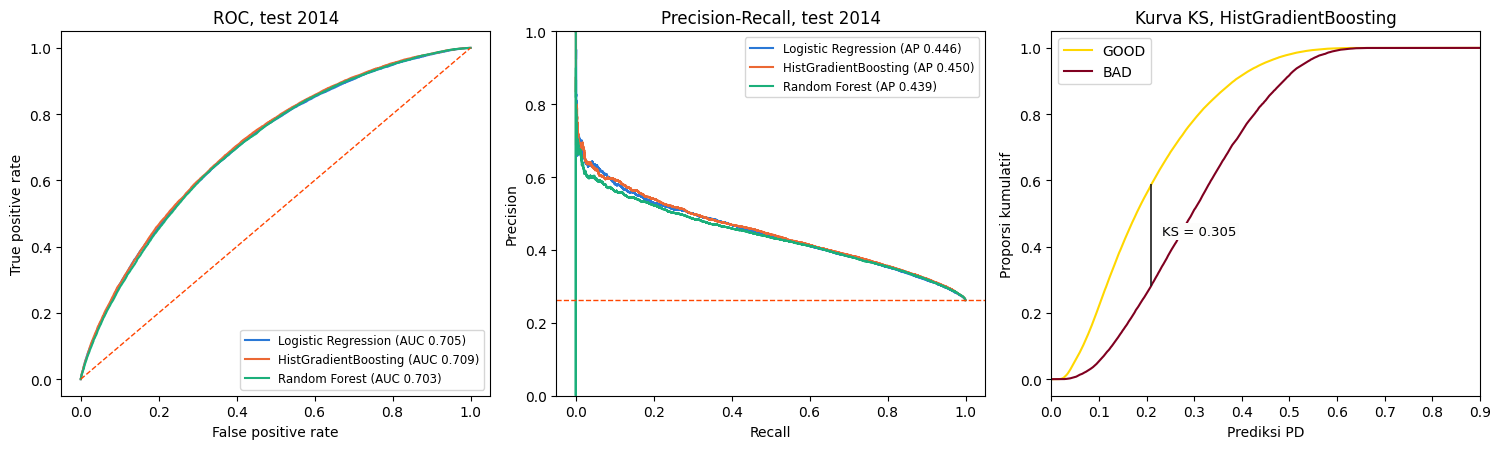

In [19]:
from sklearn.metrics import precision_recall_curve

C_INK = "#1c1c1c"  # Mendefinisikan warna tinta gelap yang hilang

BEST = summary["auc_cv"].idxmax()  # dipilih dari CV, bukan dari test
best_model = models[BEST]
p_best = proba_test[BEST]
oof_best = oof_hgb if BEST == "HistGradientBoosting" else oof_lr
print("Model terpilih berdasarkan AUC cross-validation:", BEST)
results["best_model"] = BEST

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
line_colors = {"Logistic Regression": "#2a78d6", "HistGradientBoosting": "#eb6834", "Random Forest": "#1baf7a"}
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=line_colors[name], label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rc, pr, color=line_colors[name], label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], color=C_MUTED, linestyle="--", linewidth=1)
axes[0].set(title="ROC, test 2014", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(fontsize=8.5, loc="lower right")
axes[1].axhline(y_test.mean(), color=C_MUTED, linestyle="--", linewidth=1)
axes[1].set(title="Precision-Recall, test 2014", xlabel="Recall", ylabel="Precision", ylim=(0, 1))
axes[1].legend(fontsize=8.5)

grid = np.linspace(0, 1, 401)
cdf_bad = np.searchsorted(np.sort(p_best[y_test == 1]), grid) / (y_test == 1).sum()
cdf_good = np.searchsorted(np.sort(p_best[y_test == 0]), grid) / (y_test == 0).sum()
ks_i = int(np.argmax(cdf_good - cdf_bad))
axes[2].plot(grid, cdf_good, color=C_GOOD, label="GOOD")
axes[2].plot(grid, cdf_bad, color=C_BAD, label="BAD")
axes[2].vlines(grid[ks_i], cdf_bad[ks_i], cdf_good[ks_i], color=C_INK, linewidth=1.2)
axes[2].annotate(f"KS = {cdf_good[ks_i] - cdf_bad[ks_i]:.3f}", (grid[ks_i], (cdf_bad[ks_i] + cdf_good[ks_i]) / 2),
                 textcoords="offset points", xytext=(8, 0), fontsize=9.5,
                 bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1.5))
axes[2].set(title=f"Kurva KS, {BEST}", xlabel="Prediksi PD", ylabel="Proporsi kumulatif", xlim=(0, 0.9))
axes[2].legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/06_roc_pr_ks.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

**HistGradientBoosting** terpilih karena AUC cross-validation tertinggi.

- **Kurva ROC:** makin dekat ke sudut kiri atas makin baik. Ketiga model hampir berimpit dan jauh di atas garis putus-putus.
- **Kurva Precision-Recall:** makin banyak kredit buruk ingin ditangkap (recall naik), makin banyak peminjam baik yang ikut tertuduh (precision turun).
- **Kurva KS:** garis hitam menandai jarak terbesar antara sebaran skor GOOD dan BAD, yaitu 0,306.

### 5.2 Metrik klasifikasi dan cutoff

Cutoff dipilih dari prediksi out-of-fold data latih, **bukan dari test set**, dengan
memaksimalkan KS. Test set tetap menjadi penilaian yang belum pernah dilihat.

               HistGradientBoosting @KS  HistGradientBoosting @0.5  Logistic Regression @KS
cutoff                            0.192                      0.500                    0.185
accuracy                          0.598                      0.745                    0.604
precision_bad                     0.370                      0.599                    0.372
recall_bad                        0.758                      0.082                    0.739
f1_bad                            0.497                      0.145                    0.495
specificity                       0.540                      0.980                    0.557
approval_rate                     0.462                      0.964                    0.479
tn                            29568.000                  53641.000                30465.000
fp                            25145.000                   1072.000                24248.000
fn                             4698.000                  17843.000              

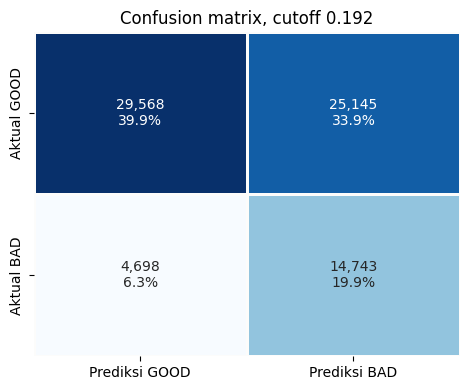

In [20]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

def clf_report(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"cutoff": float(thr), "accuracy": accuracy_score(y, pred), "precision_bad": precision_score(y, pred),
            "recall_bad": recall_score(y, pred), "f1_bad": f1_score(y, pred), "specificity": tn / (tn + fp),
            "approval_rate": float((pred == 0).mean()), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


fpr, tpr, thr = roc_curve(y_train, oof_best)
ks_cutoff = float(thr[int(np.argmax(tpr - fpr))])
rep_ks = clf_report(y_test, p_best, ks_cutoff)
rep_05 = clf_report(y_test, p_best, 0.5)
lr_fpr, lr_tpr, lr_thr = roc_curve(y_train, oof_lr)
rep_lr = clf_report(y_test, proba_test["Logistic Regression"], float(lr_thr[int(np.argmax(lr_tpr - lr_fpr))]))
print(pd.DataFrame({f"{BEST} @KS": rep_ks, f"{BEST} @0.5": rep_05, "Logistic Regression @KS": rep_lr}).round(3).to_string())
results["metrics_ks_cutoff"] = rep_ks
results["metrics_05_cutoff"] = rep_05
results["metrics_lr_ks_cutoff"] = rep_lr

fig, ax = plt.subplots(figsize=(4.8, 4))
cm = confusion_matrix(y_test, (p_best >= ks_cutoff).astype(int))
sns.heatmap(cm, annot=np.array([[f"{v:,}\n{v / cm.sum():.1%}" for v in r] for r in cm]), fmt="", cmap="Blues", cbar=False,
            xticklabels=["Prediksi GOOD", "Prediksi BAD"], yticklabels=["Aktual GOOD", "Aktual BAD"], ax=ax, linewidths=2, linecolor="#fcfcfb")
ax.set_title(f"Confusion matrix, cutoff {ks_cutoff:.3f}")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/07_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

Tabel ini menunjukkan pengaruh **cutoff**, yaitu batas skor untuk menyebut seseorang BAD.

- **Cutoff 0,19:** menangkap 75,8% kredit buruk (recall), tetapi akurasi 59,8% dan hanya 46,2% pengajuan yang lolos.
- **Cutoff 0,50:** akurasi naik ke 74,5%, tetapi hanya 8,2% kredit buruk yang tertangkap. Akurasi tinggi di sini menipu, karena model hampir selalu menebak GOOD.

**Confusion matrix (cutoff 0,19):**
- 14.743 kredit buruk tertangkap dengan benar
- 4.698 kredit buruk lolos, ini sumber kerugian
- 25.145 peminjam baik ikut ditandai berisiko, ini peluang yang hilang
- 29.568 peminjam baik lolos dengan benar

Tidak ada cutoff yang sempurna. Pilihannya bergantung pada biaya salah keputusan bagi perusahaan.

### 5.3 Kalibrasi, pengelompokan risiko, dan stabilitas skor

Band dibentuk dari desil out-of-fold data latih, 1 = risiko terendah
          n  pred_pd  bad_rate  rata_net
band                                    
1      5031    0.045     0.055   179.663
2      5103    0.075     0.084   183.854
3      5725    0.100     0.121   -52.380
4      6015    0.124     0.147  -218.964
5      6340    0.150     0.180  -414.274
6      6750    0.180     0.211  -617.718
7      7525    0.216     0.259 -1044.275
8      8864    0.262     0.298 -1394.654
9     10536    0.329     0.372 -2339.667
10    12265    0.452     0.496 -4473.952

PSI skor (train vs test): 0.088


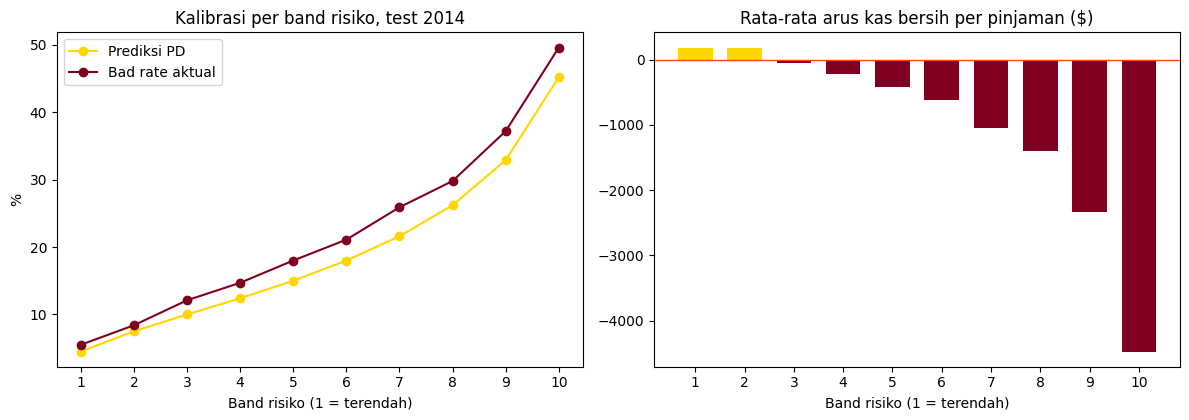

In [21]:
def psi(expected, actual, bins=10):
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, edges)[0] / len(expected)
    a = np.histogram(actual, edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


edges = np.unique(np.quantile(oof_best, np.linspace(0, 1, 11)))
edges[0], edges[-1] = -np.inf, np.inf
band = pd.DataFrame({"y": y_test.values, "p": p_best, "net": net_test.values,
                     "band": pd.cut(p_best, edges, labels=range(1, len(edges)))})
deciles = band.groupby("band", observed=False).agg(n=("y", "size"), pred_pd=("p", "mean"), bad_rate=("y", "mean"), rata_net=("net", "mean")).round(3)
print("Band dibentuk dari desil out-of-fold data latih, 1 = risiko terendah")
print(deciles.to_string())
results["deciles"] = deciles.reset_index().astype({"band": int}).to_dict(orient="records")

score_psi = psi(oof_best, p_best)
print(f"\nPSI skor (train vs test): {score_psi:.3f}")
results["psi"] = score_psi

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x = deciles.index.astype(int)
axes[0].plot(x, deciles["pred_pd"] * 100, color=C_GOOD, marker="o", label="Prediksi PD")
axes[0].plot(x, deciles["bad_rate"] * 100, color=C_BAD, marker="o", label="Bad rate aktual")
axes[0].set(title="Kalibrasi per band risiko, test 2014", xlabel="Band risiko (1 = terendah)", ylabel="%", xticks=list(x))
axes[0].legend()
axes[1].bar(x, deciles["rata_net"], color=[C_GOOD if v > 0 else C_BAD for v in deciles["rata_net"]], width=0.7)
axes[1].axhline(0, color=C_MUTED, linewidth=1)
axes[1].set(title="Rata-rata arus kas bersih per pinjaman ($)", xlabel="Band risiko (1 = terendah)", xticks=list(x))
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/08_kalibrasi_band.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

Peminjam dibagi ke 10 band risiko berdasarkan skor.

- **Bad rate naik terus** dari 5,5% (band 1) ke 49,6% (band 10). Ini bukti model mampu memeringkat risiko.
- **Kalibrasi:** prediksi sedikit di bawah kenyataan di semua band, misalnya 45,2% berbanding 49,6% di band 10. Ini sejalan dengan bad rate test yang lebih tinggi karena bias waktu.
- **PSI 0,088:** sebaran skor train dan test tidak banyak berubah, karena masih di bawah batas umum 0,1.
- **Arus kas:** rata-rata negatif mulai band 3. Angka ini jangan dibaca sebagai untung rugi sebenarnya, karena pinjaman 2014 yang sudah selesai terkena bias waktu. Pemeriksaannya ada di bagian 5.5.

### 5.4 Faktor yang paling memengaruhi risiko

Dua pandangan: *permutation importance* (seberapa turun AUC bila satu fitur diacak) untuk
model terpilih, dan koefisien Logistic Regression untuk arah pengaruhnya.

sub_grade_num            0.0728
log_annual_inc           0.0105
term_60                  0.0084
dti                      0.0073
open_acc                 0.0054
loan_to_income           0.0037
total_acc                0.0034
revol_util               0.0032
installment_to_income    0.0032
log_tot_cur_bal          0.0023
home_ownership           0.0020
purpose                  0.0019

Koefisien LR terbesar (fitur numerik sudah distandarkan):
purpose_small_business    0.481
sub_grade_num             0.323
term_60                   0.254
purpose_wedding          -0.234
purpose_credit_card      -0.227
purpose_car              -0.197
open_acc                  0.160
purpose_major_purchase   -0.152
revol_util                0.143
dti                       0.133
total_acc                -0.132
log_annual_inc           -0.127


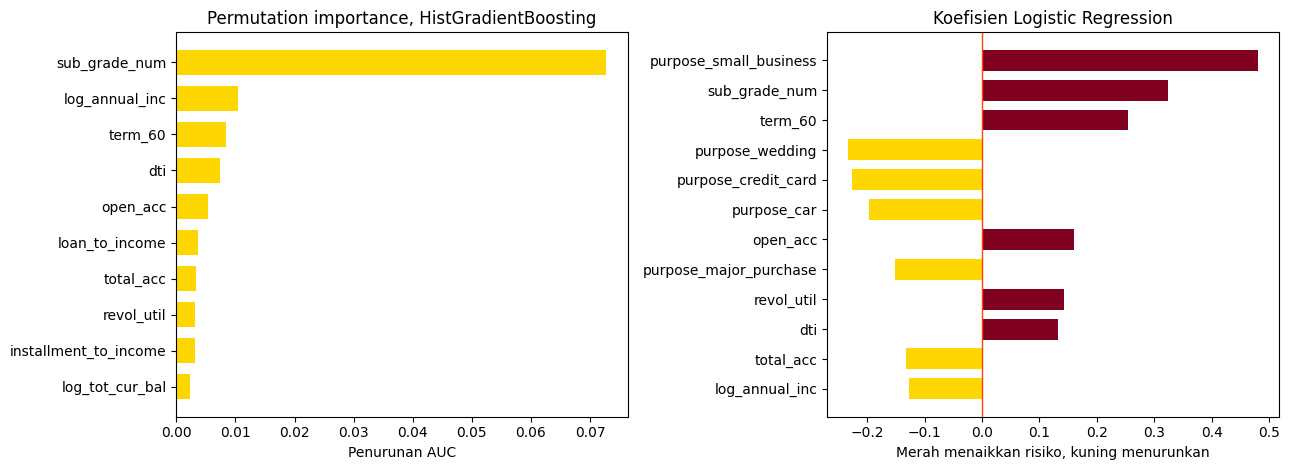

In [22]:
from sklearn.inspection import permutation_importance

idx = np.random.RandomState(SEED).choice(len(X_test), 20000, replace=False)
pi = permutation_importance(best_model, X_test[FEATURES].iloc[idx], y_test.iloc[idx], scoring="roc_auc",
                            n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
print(imp.head(12).round(4).to_string())

lr_best = lr_search.best_estimator_
coef = pd.Series(lr_best.named_steps["clf"].coef_[0], index=lr_best.named_steps["prep"].get_feature_names_out())
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
coef_top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
print("\nKoefisien LR terbesar (fitur numerik sudah distandarkan):")
print(coef_top.round(3).to_string())
results["importance"] = imp.head(10).round(4).to_dict()
results["lr_coef"] = coef_top.round(3).to_dict()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
top = imp.head(10).iloc[::-1]
axes[0].barh(top.index, top.values, color=C_GOOD, height=0.7)
axes[0].set(title=f"Permutation importance, {BEST}", xlabel="Penurunan AUC")
axes[0].grid(axis="y", visible=False)
c = coef_top.iloc[::-1]
axes[1].barh(c.index, c.values, color=[C_BAD if v > 0 else C_GOOD for v in c.values], height=0.7)
axes[1].axvline(0, color=C_MUTED, linewidth=1)
axes[1].set(title="Koefisien Logistic Regression", xlabel="Merah menaikkan risiko, kuning menurunkan")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/09_faktor_risiko.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

**Permutation importance:** bila `sub_grade_num` diacak, AUC turun 0,0728, jauh lebih besar dari fitur lain. Berikutnya pendapatan (0,0105), tenor (0,0084), dan DTI (0,0073).

**Koefisien Logistic Regression** menunjukkan arah pengaruh. Positif menaikkan risiko: `small_business`, grade lebih buruk, tenor 60 bulan, DTI, dan utilisasi tinggi. Negatif menurunkan risiko: tujuan `wedding`, `credit_card`, `car`, dan pendapatan lebih tinggi.

Ini menunjukkan hubungan dalam data, bukan bukti sebab-akibat.

### 5.5 Simulasi dampak bisnis

Arus kas bersih per pinjaman = `total_pymnt - funded_amnt` (kolom ini hanya dipakai di sini,
bukan sebagai fitur). Cutoff persetujuan dipilih dari out-of-fold data latih dengan
memaksimalkan total arus kas, lalu diterapkan ke pinjaman 2014.

Ini simulasi retrospektif di atas pinjaman yang sudah berakhir, belum memperhitungkan biaya
dana dan biaya operasional. Karena test set terkena bias pengamatan (bagian 2.1), hasilnya
diperiksa lagi pada kohort yang sudah matang.

               Setujui semua  Dengan model
cutoff          1.010000e+00  3.525000e-01
approval_rate   1.000000e+00  8.042000e-01
bad_rate        2.622000e-01  2.090000e-01
net_cash       -1.063151e+08 -4.535665e+07
bad_ditolak     0.000000e+00  3.587000e-01

Perubahan arus kas bersih: $60,958,408

Metrik test pada cutoff bisnis: {'cutoff': 0.353, 'accuracy': 0.73, 'precision_bad': 0.48, 'recall_bad': 0.359, 'f1_bad': 0.411, 'specificity': np.float64(0.862), 'approval_rate': 0.804, 'tn': 47171, 'fp': 7542, 'fn': 12467, 'tp': 6974}

Kohort matang: n=74,959, AUC out-of-fold 0.674
               Setujui semua  Dengan model
cutoff          1.010000e+00  3.525000e-01
approval_rate   1.000000e+00  9.746000e-01
bad_rate        1.309000e-01  1.261000e-01
net_cash        7.617427e+07  7.524845e+07
bad_ditolak     0.000000e+00  6.120000e-02

Kohort matang per desil risiko:
         n  pd_min  pd_max  bad_rate  rata_net    total_net
band                                                       
1    

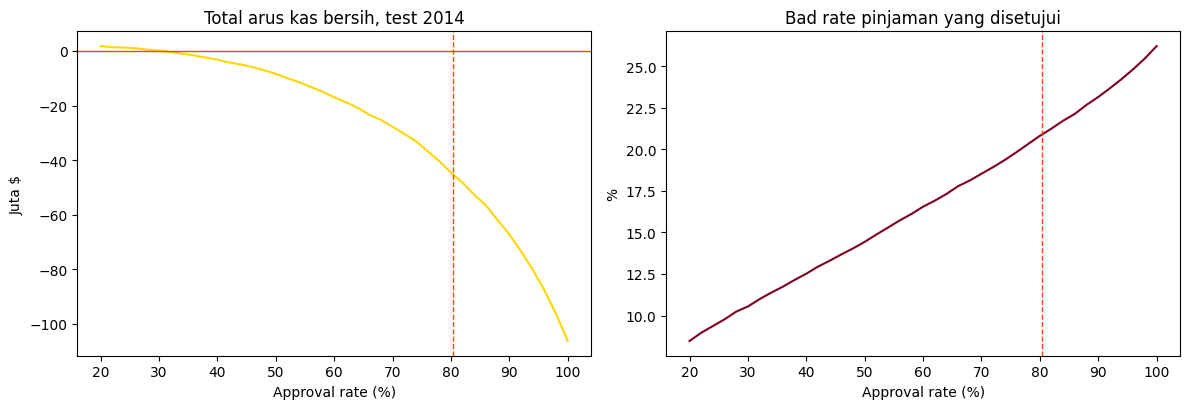

In [23]:
def policy(p, y, net, cutoff):
    ok = p < cutoff
    return {"cutoff": float(cutoff), "approval_rate": float(ok.mean()), "bad_rate": float(y[ok].mean()),
            "net_cash": float(net[ok].sum()), "bad_ditolak": float(1 - y[ok].sum() / y.sum())}


cands = np.quantile(oof_best, np.linspace(0.3, 1, 71))
cands[-1] = 1.01
train_curve = [policy(oof_best, y_train.values, net_train.values, c)["net_cash"] for c in cands]
profit_cutoff = float(cands[int(np.argmax(train_curve))])

base = policy(p_best, y_test.values, net_test.values, 1.01)
mod = policy(p_best, y_test.values, net_test.values, profit_cutoff)
print(pd.DataFrame({"Setujui semua": base, "Dengan model": mod}).round(4).to_string())
print(f"\nPerubahan arus kas bersih: ${mod['net_cash'] - base['net_cash']:,.0f}")
results["policy_base"] = base
results["policy_model"] = mod

rep_profit = clf_report(y_test, p_best, profit_cutoff)
print("\nMetrik test pada cutoff bisnis:", {k: round(v, 3) for k, v in rep_profit.items()})
results["metrics_profit_cutoff"] = rep_profit

# Pemeriksaan pada kohort matang: tenor 36 bulan, cair sampai 2012, sudah terpantau penuh.
# Skor memakai prediksi out-of-fold, jadi peminjam ini tidak dinilai oleh model yang melatihnya.
is_mature = ((X_train["term_60"] == 0) & (loan_labeled.loc[X_train.index, "issue_dt"] <= "2012-12-31")).values
m_base = policy(oof_best[is_mature], y_train.values[is_mature], net_train.values[is_mature], 1.01)
m_mod = policy(oof_best[is_mature], y_train.values[is_mature], net_train.values[is_mature], profit_cutoff)
m_auc = roc_auc_score(y_train.values[is_mature], oof_best[is_mature])
print(f"\nKohort matang: n={is_mature.sum():,}, AUC out-of-fold {m_auc:.3f}")
print(pd.DataFrame({"Setujui semua": m_base, "Dengan model": m_mod}).round(4).to_string())
results["mature_cohort"] = {"n": int(is_mature.sum()), "auc": float(m_auc), "base": m_base, "model": m_mod}

# Berapa arus kas tiap kelompok risiko pada kohort matang, dan cutoff terbaik jika dilihat di kohort ini.
m_edges = np.quantile(oof_best[is_mature], np.linspace(0, 1, 11))
m_edges[0], m_edges[-1] = -np.inf, np.inf
m_tab = pd.DataFrame({"y": y_train.values[is_mature], "net": net_train.values[is_mature], "p": oof_best[is_mature]})
m_tab["band"] = pd.cut(m_tab["p"], m_edges, labels=range(1, 11))
m_band = m_tab.groupby("band", observed=False).agg(n=("y", "size"), pd_min=("p", "min"), pd_max=("p", "max"), bad_rate=("y", "mean"), rata_net=("net", "mean"), total_net=("net", "sum")).round(3)
print("\nKohort matang per desil risiko:")
print(m_band.to_string())
m_cands = np.quantile(oof_best[is_mature], np.linspace(0.3, 1, 71))
m_cands[-1] = 1.01
m_curve = [policy(oof_best[is_mature], y_train.values[is_mature], net_train.values[is_mature], c) for c in m_cands]
m_best = max(m_curve, key=lambda r: r["net_cash"])
print("Cutoff terbaik di kohort matang (in-sample, hanya indikatif):", {k: round(v, 4) for k, v in m_best.items()})
results["mature_cohort"]["best"] = m_best
results["mature_cohort"]["bands"] = m_band.reset_index().astype({"band": int}).to_dict(orient="records")

curve = pd.DataFrame([policy(p_best, y_test.values, net_test.values, c) for c in np.quantile(p_best, np.linspace(0.2, 1, 41)[:-1]).tolist() + [1.01]])
results["policy_curve"] = curve[["approval_rate", "bad_rate", "net_cash"]].round(4).to_dict(orient="list")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(curve["approval_rate"] * 100, curve["net_cash"] / 1e6, color=C_GOOD)
axes[0].axvline(mod["approval_rate"] * 100, color=C_MUTED, linestyle="--", linewidth=1)
axes[0].axhline(0, color=C_MUTED, linewidth=1)
axes[0].set(title="Total arus kas bersih, test 2014", xlabel="Approval rate (%)", ylabel="Juta $")
axes[1].plot(curve["approval_rate"] * 100, curve["bad_rate"] * 100, color=C_BAD)
axes[1].axvline(mod["approval_rate"] * 100, color=C_MUTED, linestyle="--", linewidth=1)
axes[1].set(title="Bad rate pinjaman yang disetujui", xlabel="Approval rate (%)", ylabel="%")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/10_simulasi_bisnis.png", dpi=150, bbox_inches="tight")
plt.show()

**Penjelasan hasil**

**Sel ini perlu dibaca hati-hati.**

**Pada data test 2014:** cutoff 0,35 menyetujui 80,4% pengajuan, menurunkan bad rate dari 26,22% ke 20,90%, dan menolak 35,9% kredit buruk. Arus kas terlihat naik \$61,0 juta, dari -\$106,3 juta ke -\$45,4 juta. Grafiknya juga terlihat makin baik saat approval diperketat. Namun kerugian ini sebagian besar akibat bias waktu, sebab pinjaman 2014 yang berjalan baik belum masuk hitungan.

**Pada kohort matang:** AUC 0,674 dan semua desil risiko tetap untung, bahkan desil paling berisiko masih rata-rata +\$697 per pinjaman. Cutoff yang sama menurunkan total arus kas dari \$76,17 juta ke \$75,25 juta.

**Kesimpulannya:** model terbukti menurunkan risiko, tetapi kenaikan profit belum terbukti. Biaya dana dan biaya operasional juga belum dihitung.

### 5.6 Uji ketahanan

1. **Tanpa skor LC:** perusahaan lain mungkin tidak punya `sub_grade`.
2. **Dengan `int_rate`:** apakah membuang suku bunga merugikan?
3. **Pembagian acak:** seberapa optimistis split acak dibanding out-of-time?
4. **Demonstrasi leakage:** apa yang terjadi kalau kolom pasca-pencairan ikut dipakai?

In [24]:
from sklearn.model_selection import train_test_split

def auc_variant(columns, Xtr=None, ytr=None, Xte=None, yte=None, base=None):
    Xtr, ytr, Xte, yte = (X_train, y_train, X_test, y_test) if Xtr is None else (Xtr, ytr, Xte, yte)
    base = hgb_search.best_estimator_ if base is None else base
    scale = "scale" in base.named_steps["prep"].transformers[0][1].named_steps
    pipe = Pipeline([("prep", make_preprocessor(columns, scale=scale)), ("clf", clone(base.named_steps["clf"]))])
    pipe.fit(Xtr[columns], ytr)
    return float(roc_auc_score(yte, pipe.predict_proba(Xte[columns])[:, 1]))


no_lc = [c for c in FEATURES if c != "sub_grade_num"]
Xa, Xb, ya, yb = train_test_split(loan_features, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
robust = {"Model utama": roc_auc_score(y_test, proba_test["HistGradientBoosting"]),
          "Tanpa sub_grade": auc_variant(no_lc),
          "Ditambah int_rate": auc_variant(FEATURES + ["int_rate"]),
          "Split acak 80/20": auc_variant(FEATURES, Xa, ya, Xb, yb)}

leak_cols = ["total_rec_prncp", "recoveries", "last_pymnt_amnt"]
X_leak = pd.concat([loan_features[FEATURES], loan_labeled[leak_cols]], axis=1)
leak_feats = FEATURES + leak_cols
robust["Dengan kolom leakage (tidak valid)"] = auc_variant(leak_feats, X_leak[is_train], y_train, X_leak[~is_train], y_test,
                                                          base=lr_search.best_estimator_)
print(pd.Series(robust).round(4).to_string())
results["robustness"] = {k: round(v, 4) for k, v in robust.items()}

by_term = {t: roc_auc_score(y_test[X_test["term_60"] == v], p_best[X_test["term_60"] == v]) for t, v in [("36 bulan", 0), ("60 bulan", 1)]}
print("\nAUC test per tenor:", {k: round(v, 3) for k, v in by_term.items()})
results["auc_by_term"] = {k: round(v, 4) for k, v in by_term.items()}

Model utama                           0.7088
Tanpa sub_grade                       0.7023
Ditambah int_rate                     0.7081
Split acak 80/20                      0.7194
Dengan kolom leakage (tidak valid)    0.9993

AUC test per tenor: {'36 bulan': np.float64(0.704), '60 bulan': np.float64(0.663)}


**Penjelasan hasil**

- **Tanpa `sub_grade`:** AUC hanya turun ke 0,7023, jadi model tetap berguna tanpa skor LC.
- **Ditambah `int_rate`:** AUC 0,7081, tidak lebih baik, jadi keputusan membuangnya tidak merugikan.
- **Split acak:** AUC 0,7194, lebih tinggi dari 0,7088. Pembagian acak terlihat lebih bagus, tetapi terlalu optimistis.
- **Dengan kolom leakage:** AUC 0,9993. Nyaris sempurna tetapi palsu, karena memakai data pembayaran yang belum ada saat pengajuan.
- **Per tenor:** model lebih lemah pada tenor 60 bulan (0,663) dibanding 36 bulan (0,704).

### 5.7 Sample prediction

Bagian ini menunjukkan cara model dipakai untuk pengajuan baru: data mentah masuk, lalu keluar peluang gagal bayar dan tindakan yang disarankan.

Tiga profil pertama adalah **contoh buatan** untuk ilustrasi, bukan orang sungguhan. `sub_grade` tetap harus diisi karena menjadi salah satu fitur model.

In [25]:
def recommend(pd_score):
    """Mengubah peluang gagal bayar menjadi tindakan, memakai dua cutoff dari data latih."""
    if pd_score < ks_cutoff:
        return "Proses cepat"
    if pd_score < profit_cutoff:
        return "Tinjau manual"
    return "Tolak atau minta jaminan"


def predict_applications(applications):
    """Menerima data mentah per pengajuan, mengembalikan peluang gagal bayar dan tindakan."""
    features = build_features(applications)[FEATURES]
    scores = best_model.predict_proba(features)[:, 1]
    return pd.DataFrame({"peluang_gagal_bayar": scores.round(3),
                         "tindakan": [recommend(v) for v in scores]}, index=applications.index)


common = {"issue_d": "Jan-15", "pub_rec": 0, "delinq_2yrs": 0, "collections_12_mths_ex_med": 0,
          "acc_now_delinq": 0, "tot_coll_amt": 0, "mths_since_last_record": np.nan, "verification_status": "Verified"}
sample_applicants = pd.DataFrame([
    {**common, "loan_amnt": 8000, "term": " 36 months", "sub_grade": "A2", "int_rate": 7.5, "installment": 249, "annual_inc": 95000,
     "emp_length": "10+ years", "home_ownership": "MORTGAGE", "purpose": "car", "dti": 8.0, "earliest_cr_line": "Mar-98",
     "inq_last_6mths": 0, "open_acc": 9, "total_acc": 25, "revol_bal": 5000, "revol_util": 20.0, "tot_cur_bal": 180000,
     "total_rev_hi_lim": 25000, "mths_since_last_delinq": np.nan},
    {**common, "loan_amnt": 15000, "term": " 36 months", "sub_grade": "C3", "int_rate": 14.0, "installment": 513, "annual_inc": 60000,
     "emp_length": "4 years", "home_ownership": "RENT", "purpose": "debt_consolidation", "dti": 18.0, "earliest_cr_line": "Jun-06",
     "inq_last_6mths": 1, "open_acc": 11, "total_acc": 22, "revol_bal": 12000, "revol_util": 60.0, "tot_cur_bal": 40000,
     "total_rev_hi_lim": 20000, "mths_since_last_delinq": 40.0},
    {**common, "loan_amnt": 30000, "term": " 60 months", "sub_grade": "F2", "int_rate": 23.0, "installment": 846, "annual_inc": 42000,
     "emp_length": "1 year", "home_ownership": "RENT", "purpose": "small_business", "dti": 32.0, "earliest_cr_line": "Sep-10",
     "inq_last_6mths": 3, "open_acc": 14, "total_acc": 18, "revol_bal": 18000, "revol_util": 92.0, "tot_cur_bal": 30000,
     "total_rev_hi_lim": 20000, "mths_since_last_delinq": 8.0},
], index=["Contoh A (risiko rendah)", "Contoh B (risiko menengah)", "Contoh C (risiko tinggi)"])

print("Profil buatan:")
sample_result = predict_applications(sample_applicants)
print(sample_result.to_string())
results["sample_prediction"] = sample_result.reset_index().to_dict(orient="records")

# Pinjaman 2014 sungguhan yang dipilih acak, supaya prediksi bisa dibandingkan dengan hasil aslinya.
real_sample = loan_labeled[~is_train].sample(8, random_state=SEED)
real_result = predict_applications(real_sample)
real_result.insert(0, "sub_grade", real_sample["sub_grade"])
real_result["hasil_asli"] = real_sample["target"].map({0: "GOOD", 1: "BAD"})
print("\nPinjaman 2014 yang dipilih acak:")
print(real_result.reset_index(drop=True).to_string())


Profil buatan:
                            peluang_gagal_bayar                  tindakan
Contoh A (risiko rendah)                  0.024              Proses cepat
Contoh B (risiko menengah)                0.194             Tinjau manual
Contoh C (risiko tinggi)                  0.630  Tolak atau minta jaminan

Pinjaman 2014 yang dipilih acak:
  sub_grade  peluang_gagal_bayar       tindakan hasil_asli
0        A4                0.048   Proses cepat       GOOD
1        C3                0.236  Tinjau manual        BAD
2        C4                0.180   Proses cepat       GOOD
3        A4                0.075   Proses cepat       GOOD
4        D4                0.258  Tinjau manual       GOOD
5        F3                0.332  Tinjau manual       GOOD
6        D4                0.239  Tinjau manual       GOOD
7        B4                0.162   Proses cepat       GOOD


**Penjelasan hasil**

**Tiga profil buatan** menunjukkan cara membaca hasil model: makin buruk grade, makin panjang tenor, dan makin berat beban utang, peluang gagal bayarnya makin tinggi. Tindakannya mengikuti dua cutoff: di bawah 0,19 proses cepat, 0,19 sampai 0,35 tinjau manual, dan 0,35 ke atas tolak atau minta jaminan.

**Delapan pinjaman 2014 sungguhan** bisa dibandingkan dengan hasil aslinya di kolom `hasil_asli`. Peluang gagal bayar bukan vonis: peminjam dengan peluang cukup tinggi pun masih mungkin melunasi. Delapan baris ini hanya contoh dan terlalu sedikit untuk menilai kinerja model, yang tetap dinilai dari seluruh data test di bagian 4.4 dan 5.2.

In [26]:
import json

with open(f"{OUTPUT_DIR}/results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Tersimpan:", f"{OUTPUT_DIR}/results.json")

Tersimpan: ./results.json


## 6. Kesimpulan dan rekomendasi

**Kinerja model terbaik (HistGradientBoosting) pada pinjaman 2014 yang tidak pernah dilihat:** AUC 0,709, Gini 0,418, KS 0,306, dan PSI 0,088 (skor stabil, di bawah batas umum 0,1). Model memeringkat risiko dengan baik: bad rate naik dari 5,5% di band teraman ke 49,6% di band paling berisiko.

**Akurasi bukan ukuran yang tepat di sini.** Menebak semua GOOD memberi akurasi 73,8% di test, sedangkan cutoff KS hanya 59,8% tetapi menangkap 75,8% kredit buruk.

**Usulan kebijakan bertingkat (angka dari test 2014):**

| Prediksi PD | Tindakan | Porsi pengajuan | Bad rate aktual |
|---|---|---|---|
| Di bawah 0,19 | Proses cepat | 46,2% | 13,7% |
| 0,19 sampai 0,35 | Tinjau manual, sesuaikan plafon atau tenor | 34,2% | 30,6% |
| 0,35 ke atas | Tolak atau minta jaminan | 19,6% | 48,0% |

Bila hanya kelompok terakhir yang ditolak, bad rate portofolio turun dari 26,2% ke 20,9%.

**Klaim keuntungan belum bisa dibuat.** Simulasi di test menunjukkan arus kas naik \$61,0 juta, tetapi angka ini **tidak boleh dipakai sebagai estimasi manfaat**, karena test hanya berisi pinjaman 2014 yang sudah berakhir. Pada kohort matang (36 bulan, cair sampai 2012), semua desil risiko masih menghasilkan arus kas positif, dan menolak kelompok berisiko tidak menambah total arus kas (turun dari \$76,17 juta ke \$75,25 juta). Biaya dana dan biaya operasional juga belum dihitung. Jadi model paling aman diposisikan sebagai alat **memeringkat risiko, membantu penentuan harga, dan memprioritaskan tinjauan**. Cutoff tolak harus ditetapkan bersama klien memakai data biaya mereka.

**Keterbatasan**

1. Hanya pinjaman yang disetujui, tanpa data penolakan (*selection bias*).
2. Label terkena bias karena pinjaman `Current` dikeluarkan, terutama untuk 2013-2014. AUC tenor 60 bulan juga lebih lemah (0,663 berbanding 0,704).
3. `sub_grade` adalah hasil skoring LC. Tanpanya AUC hanya turun ke 0,702, jadi model tetap berguna bagi klien yang tidak punya skor tersebut, setelah dilatih ulang pada data mereka.
4. Split acak memberi AUC 0,719, lebih optimistis dari out-of-time 0,709. Memakai kolom pasca-pencairan memberi AUC 0,999 yang sepenuhnya palsu.
5. Data 2007-2014 berasal dari pasar yang berbeda, jadi perlu validasi ulang sebelum dipakai pada portofolio Indonesia.

**Langkah berikutnya:** validasi pada data klien, tambah skor biro kredit, buat model waktu-ke-gagal (*survival analysis*) agar pinjaman `Current` tetap terpakai, dan pantau PSI setiap bulan.